In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_path = Path("../data/SVM_pred_comp.csv")
df = pd.read_csv(data_path)

n = len(df)
old_correct = int((df["prev_pred"] == df["true_class"]).sum())
new_correct = int((df["new_pred"] == df["true_class"]).sum())
old_pos = int((df["prev_pred"] == 1).sum())
new_pos = int((df["new_pred"] == 1).sum())

metrics = pd.DataFrame(
    {
        "accuracy": [
            f"{100 * old_correct / n:.1f}% ({old_correct}/{n})",
            f"{100 * new_correct / n:.1f}% ({new_correct}/{n})",
        ],
        "positive predictions (pred=1)": [old_pos, new_pos],
    },
    index=["Original SVM", "Expanded SVM"],
)
metrics

,accuracy,positive predictions (pred=1)
Original SVM,45.2% (14/31),25
Expanded SVM,83.9% (26/31),21


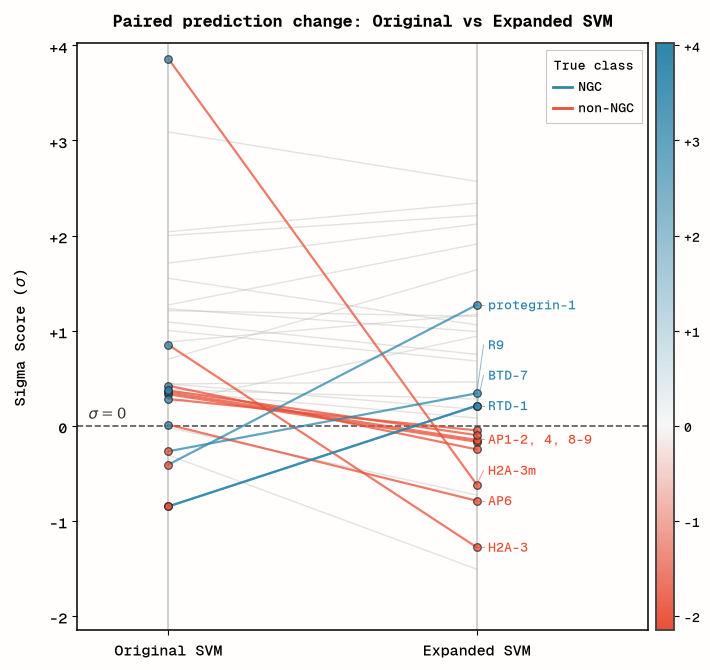

,n,mean_prev_sigma,mean_new_sigma,n_flip,delta
true_class,,,,,
non-NGC-inducing (0),15,0.706667,-0.180667,8,-0.887333
NGC-inducing (1),16,0.799375,1.225625,4,0.426250


In [12]:
# Paired slope graph: Original SVM vs Expanded SVM sigma score
# Colored by true class; non-flipping samples drawn at lower opacity

from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
from pathlib import Path

font_dir = Path("../fonts")
for ttf in font_dir.glob("GeistMono-*.ttf"):
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams["font.family"] = "Geist Mono"
plt.rcParams["font.weight"] = "normal"
label_font = font_manager.FontProperties(fname=str(font_dir / "GeistMono-Medium.ttf"), size=9)
axis_font = font_manager.FontProperties(fname=str(font_dir / "GeistMono-Medium.ttf"), size=11)
title_font = font_manager.FontProperties(fname=str(font_dir / "GeistMono-Bold.ttf"), size=12)
legend_font = font_manager.FontProperties(fname=str(font_dir / "GeistMono-Medium.ttf"), size=9)

BG_COLOR = "#fffefdff"  # adjustable plot background

fig, ax = plt.subplots(figsize=(7.2, 6.8), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

class_styles = {
    1: {"color": "#2E86AB", "label": "NGC-inducing (1)", "zorder": 3},
    0: {"color": "#E94F37", "label": "non-NGC-inducing (0)", "zorder": 2},
}

x_left, x_right = 0, 1.35
df = df.assign(flipped=df["prev_pred"] != df["new_pred"])

# Non-flips in gray (background); flips colored on top
for flipped in [False, True]:
    for true_cls, style in class_styles.items():
        subset = df[(df["true_class"] == true_cls) & (df["flipped"] == flipped)]
        color = style["color"] if flipped else "#B0B0B0"
        alpha = 0.75 if flipped else 0.35
        lw = 1.6 if flipped else 1.0
        z = style["zorder"] + (2 if flipped else 0)
        for _, row in subset.iterrows():
            ax.plot(
                [x_left, x_right],
                [row["prev_sigma"], row["new_sigma"]],
                color=color,
                alpha=alpha,
                linewidth=lw,
                zorder=z,
            )
            if flipped:
                # Dots follow prediction sign; line keeps true-class color
                for x, sigma in ((x_left, row["prev_sigma"]), (x_right, row["new_sigma"])):
                    pred_color = (
                        class_styles[1]["color"]
                        if sigma >= 0
                        else class_styles[0]["color"]
                    )
                    ax.scatter(
                        [x],
                        [sigma],
                        color=pred_color,
                        s=30,
                        alpha=alpha,
                        zorder=z + 1,
                        edgecolors="#222222",
                        linewidths=0.9,
                    )

def format_ap_ranges(nums):
    nums = sorted(nums)
    ranges, start, prev = [], nums[0], nums[0]
    for n in nums[1:]:
        if n == prev + 1:
            prev = n
        else:
            ranges.append((start, prev))
            start = prev = n
    ranges.append((start, prev))
    parts = []
    for i, (a, b) in enumerate(ranges):
        if a == b:
            parts.append(str(a) if i else f"AP{a}")
        else:
            parts.append(f"{a}-{b}" if i else f"AP{a}-{b}")
    return ", ".join(parts)


flips = df[df["flipped"]].copy()
ap_mask = flips["id"].str.match(r"^AP([1-9]|10)$")
# AP outliers (e.g. ~0 → strongly negative) get their own labels
ap_outlier_ids = {"AP6"}
ap_flips = flips[ap_mask & ~flips["id"].isin(ap_outlier_ids)]
other_flips = flips[~ap_mask | flips["id"].isin(ap_outlier_ids)]

# Collect labels, then space y positions to avoid overlap
label_items = []
for _, row in other_flips.iterrows():
    label_items.append(
        {
            "text": row["id"],
            "y_pref": float(row["new_sigma"]),
            "color": class_styles[row["true_class"]]["color"],
        }
    )
if len(ap_flips):
    ap_nums = ap_flips["id"].str.extract(r"AP(\d+)")[0].astype(int).tolist()
    label_items.append(
        {
            "text": format_ap_ranges(ap_nums),
            "y_pref": float(ap_flips["new_sigma"].mean()),
            "color": class_styles[0]["color"],
        }
    )

label_items = sorted(label_items, key=lambda d: d["y_pref"])
min_gap = 0.32
ys = [d["y_pref"] for d in label_items]
for i in range(1, len(ys)):
    if ys[i] - ys[i - 1] < min_gap:
        ys[i] = ys[i - 1] + min_gap
# Pull back from the top if needed, then re-enforce gaps upward
for i in range(len(ys) - 2, -1, -1):
    if ys[i + 1] - ys[i] < min_gap:
        ys[i] = ys[i + 1] - min_gap

for item, y in zip(label_items, ys):
    ax.plot(
        [x_right, x_right + 0.03],
        [item["y_pref"], y],
        color=item["color"],
        linewidth=0.7,
        alpha=0.55,
        zorder=9,
        solid_capstyle="round",
    )
    ax.text(
        x_right + 0.05,
        y,
        item["text"],
        ha="left",
        va="center",
        fontproperties=label_font,
        color=item["color"],
        zorder=10,
    )

ax.axhline(0, color="#444444", linestyle="--", linewidth=1.2, alpha=0.9, zorder=1)
ax.axvline(x_left, color="#C8C8C8", linewidth=1.2, zorder=0)
ax.axvline(x_right, color="#C8C8C8", linewidth=1.2, zorder=0)
sigma_vals = df[["prev_sigma", "new_sigma"]].to_numpy().ravel()
y_range = sigma_vals.max() - sigma_vals.min()
pad_lo = 0.12 * y_range
pad_hi = 0.03 * y_range  # tight top — little data near the max
ax.set_xlim(-0.4, 2.1)
y_lo = min(sigma_vals.min() - pad_lo, min(ys) - 0.15)
y_hi = max(sigma_vals.max() + pad_hi, max(ys) + 0.1)
ax.set_ylim(y_lo, y_hi)

ax.set_xticks([x_left, x_right])
ax.set_xticklabels(["Original SVM", "Expanded SVM"], fontproperties=axis_font)
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda v, _: "0" if abs(v) < 1e-9 else f"{v:+.0f}")
)
for tick_label in ax.get_yticklabels():
    tick_label.set_fontproperties(axis_font)
ax.set_ylabel("Sigma Score ($\\sigma$)", fontproperties=axis_font, labelpad=14)
ax.set_title(
    "Paired prediction change: Original vs Expanded SVM",
    fontproperties=title_font,
    pad=12,
)
ax.text(
    -0.35,
    0.02,
    r"$\sigma = 0$",
    ha="left",
    va="bottom",
    fontsize=11,
    color="#333333",
)

legend_handles = [
    Line2D([0], [0], color=class_styles[1]["color"], lw=2, label="NGC"),
    Line2D([0], [0], color=class_styles[0]["color"], lw=2, label="non-NGC"),
]
leg = ax.legend(
    handles=legend_handles,
    title="True class",
    loc="upper right",
    frameon=True,
    fancybox=False,
    facecolor=BG_COLOR,
    edgecolor="#C8C8C8",
    framealpha=1,
    borderpad=0.6,
    handlelength=1.5,
    handletextpad=0.5,
    labelspacing=0.4,
    prop=legend_font,
    title_fontproperties=legend_font,
)
leg.get_frame().set_linewidth(0.8)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.1)

# Right-side color scale aligned to plot y-axis (linear; 0 matches plot σ = 0)
zero_frac = (0.0 - y_lo) / (y_hi - y_lo)
pred_cmap = LinearSegmentedColormap.from_list(
    "pred_sign",
    [
        (0.0, class_styles[0]["color"]),
        (zero_frac, "#F7F7F7"),
        (1.0, class_styles[1]["color"]),
    ],
)
pred_norm = Normalize(vmin=y_lo, vmax=y_hi)
pred_sm = plt.cm.ScalarMappable(cmap=pred_cmap, norm=pred_norm)
pred_sm.set_array([])

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3.2%", pad=0.08)
cbar = fig.colorbar(pred_sm, cax=cax)
cbar.ax.set_ylim(y_lo, y_hi)
cbar.set_ticks([t for t in ax.get_yticks() if y_lo <= t <= y_hi])
cbar.ax.yaxis.set_major_formatter(
    FuncFormatter(lambda v, _: "0" if abs(v) < 1e-9 else f"{v:+.0f}")
)
for tick_label in cbar.ax.get_yticklabels():
    tick_label.set_fontproperties(label_font)
cbar.outline.set_visible(True)
cbar.outline.set_edgecolor("#444444")
cbar.outline.set_linewidth(1.1)
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#444444")
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

summary = (
    df.groupby("true_class")
    .agg(
        n=("id", "count"),
        mean_prev_sigma=("prev_sigma", "mean"),
        mean_new_sigma=("new_sigma", "mean"),
        n_flip=("flipped", "sum"),
    )
    .assign(delta=lambda x: x["mean_new_sigma"] - x["mean_prev_sigma"])
)
summary.index = summary.index.map({1: "NGC-inducing (1)", 0: "non-NGC-inducing (0)"})
summary